# Rock Paper Scissors: Comparing YOLOv8 Model Sizes and Hyperparameters

This notebook trains several experiments on the same dataset, then produces a comparison table (Precision, Recall, mAP) and picks the best model.

**Before running:** go to `Runtime > Change runtime type`, choose **T4 GPU**, then run the cells in order.

## 1. Install

In [ ]:
!pip install -q ultralytics roboflow

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT FOUND - enable T4 GPU")

GPU: Tesla T4


## 2. Download the dataset from Roboflow

The cell asks for the API key when it runs, so the key is never saved inside the notebook if you share it.

In [ ]:
from getpass import getpass
from roboflow import Roboflow

rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("janas-workspace-pwjua").project("rock-paper-scissors-tgfhs")
dataset = project.version(3).download("yolov8")

DATA = f"{dataset.location}/data.yaml"
print(DATA)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to rock-paper-scissors-3 in yolov8:: 100%|██████████| 660/660 [00:00<00:00, 10564.88it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
/content/rock-paper-scissors-3/data.yaml


## 3. Where results are saved

Set `SAVE_TO_DRIVE = True` to save results to Google Drive. If Colab disconnects, re-run the notebook and it continues from the last finished experiment.

In [ ]:
from pathlib import Path

SAVE_TO_DRIVE = False

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/rps_runs")
else:
    RUNS = Path("/content/rps_runs")

SUMMARIES = RUNS / "summaries"
SUMMARIES.mkdir(parents=True, exist_ok=True)

## 4. Experiments

`BASE` holds the shared settings, and each experiment changes only one thing, so we know what caused any difference.

| Experiment | What it tests |
|---|---|
| `n_base` / `s_base` / `m_base` | Model size: nano, small, medium |
| `s_sgd_lr0.01` | SGD optimizer with learning rate 0.01 |
| `s_adamw_lr0.0005` | AdamW optimizer with a lower learning rate |
| `s_img416` | Smaller image size (faster, possibly less accurate) |
| `s_batch8` | Smaller batch size |
| `s_no_mosaic` | Mosaic turned off, since Roboflow already augmented the data |

Note: in the base experiments the optimizer is `auto`, which means YOLO picks the optimizer and learning rate itself and ignores `lr0`. That is why the learning-rate experiments set the optimizer explicitly.

You can add or remove any line in the list.

In [ ]:
BASE = dict(epochs=80, imgsz=640, batch=16, patience=20, seed=0)

EXPERIMENTS = [
    # model size
    dict(name="n_base", model="yolov8n.pt"),
    dict(name="s_base", model="yolov8s.pt"),
    dict(name="m_base", model="yolov8m.pt"),
    # hyperparameters (all on yolov8s, one change each)
    dict(name="s_sgd_lr0.01", model="yolov8s.pt", optimizer="SGD", lr0=0.01),
    dict(name="s_adamw_lr0.0005", model="yolov8s.pt", optimizer="AdamW", lr0=0.0005),
    dict(name="s_img416", model="yolov8s.pt", imgsz=416),
    dict(name="s_batch8", model="yolov8s.pt", batch=8),
    dict(name="s_no_mosaic", model="yolov8s.pt", mosaic=0.0),
]

## 5. Training and evaluation

Each experiment is trained, then its best weights (`best.pt`) are evaluated on the validation and test sets. Experiments that already finished are skipped.

In [ ]:
import json
import time

import pandas as pd
from ultralytics import YOLO


def evaluate(weights, split, imgsz):
    m = YOLO(weights).val(data=DATA, split=split, imgsz=imgsz, plots=False, verbose=False)
    per_class = {
        m.names[int(c)]: dict(
            precision=float(m.box.p[i]),
            recall=float(m.box.r[i]),
            map50=float(m.box.ap50[i]),
            map5095=float(m.box.ap[i]),
        )
        for i, c in enumerate(m.box.ap_class_index)
    }
    return dict(
        precision=float(m.box.mp),
        recall=float(m.box.mr),
        map50=float(m.box.map50),
        map5095=float(m.box.map),
        inference_ms=float(m.speed["inference"]),
        per_class=per_class,
    )


records = []
for exp in EXPERIMENTS:
    cfg = {**BASE, **exp}
    name = cfg.pop("name")
    weights = cfg.pop("model")
    summary_file = SUMMARIES / f"{name}.json"

    if summary_file.exists():
        print(f"[skip] {name} already done")
        records.append(json.loads(summary_file.read_text()))
        continue

    print(f"\n===== {name} =====")
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=DATA, project=str(RUNS), name=name, exist_ok=True, verbose=False, **cfg)
    train_min = (time.time() - t0) / 60

    run_dir = Path(model.trainer.save_dir)
    best = run_dir / "weights" / "best.pt"

    try:
        test_metrics = evaluate(best, "test", cfg["imgsz"])
    except Exception as e:
        print("test split not evaluated:", e)
        test_metrics = None

    rec = dict(
        name=name,
        model=weights.replace(".pt", ""),
        settings=cfg,
        epochs_run=len(pd.read_csv(run_dir / "results.csv")),
        train_min=round(train_min, 1),
        size_mb=round(best.stat().st_size / 1e6, 1),
        run_dir=str(run_dir),
        best=str(best),
        val=evaluate(best, "val", cfg["imgsz"]),
        test=test_metrics,
    )
    summary_file.write_text(json.dumps(rec, indent=2))
    records.append(rec)

print("\nDone:", len(records), "experiments")


===== n_base =====
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rock-paper-scissors-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=n_base, nbs=64, nms=None, ops

## 6. Comparison table

Sorted by `val_mAP50-95` and saved as `comparison.csv`.

**Note:** the validation and test sets are small, so a difference of two or three mAP points between experiments may be chance rather than a real improvement.

In [ ]:
rows = []
for r in records:
    s = r["settings"]
    t = r["test"] or {}
    rows.append(
        {
            "experiment": r["name"],
            "model": r["model"],
            "imgsz": s["imgsz"],
            "batch": s["batch"],
            "optimizer": s.get("optimizer", "auto"),
            "lr0": s.get("lr0", "auto"),
            "mosaic": s.get("mosaic", 1.0),
            "epochs_run": r["epochs_run"],
            "train_min": r["train_min"],
            "size_mb": r["size_mb"],
            "inference_ms": round(r["val"]["inference_ms"], 1),
            "val_precision": r["val"]["precision"],
            "val_recall": r["val"]["recall"],
            "val_mAP50": r["val"]["map50"],
            "val_mAP50-95": r["val"]["map5095"],
            "test_mAP50": t.get("map50"),
            "test_mAP50-95": t.get("map5095"),
        }
    )

df = pd.DataFrame(rows).sort_values("val_mAP50-95", ascending=False).reset_index(drop=True)
df.to_csv(RUNS / "comparison.csv", index=False)
df.round(3)

,experiment,model,imgsz,batch,optimizer,lr0,mosaic,epochs_run,train_min,size_mb,inference_ms,val_precision,val_recall,val_mAP50,val_mAP50-95,test_mAP50,test_mAP50-95
0,s_base,yolov8s,640,16,auto,auto,1.0,80,7.3,22.5,9.8,0.952,0.852,0.973,0.868,0.882,0.826
1,s_adamw_lr0.0005,yolov8s,640,16,AdamW,0.0005,1.0,54,5.4,22.5,9.7,0.931,0.882,0.951,0.859,0.946,0.888
2,n_base,yolov8n,640,16,auto,auto,1.0,80,5.7,6.5,5.3,0.901,0.909,0.946,0.842,0.929,0.896
3,s_sgd_lr0.01,yolov8s,640,16,SGD,0.01,1.0,65,5.3,22.5,10.0,0.945,0.935,0.970,0.839,0.891,0.783
4,s_img416,yolov8s,416,16,auto,auto,1.0,80,6.7,22.5,6.0,0.948,0.832,0.946,0.836,0.948,0.901
5,s_batch8,yolov8s,640,8,auto,auto,1.0,80,10.5,22.5,9.8,0.984,0.879,0.943,0.830,0.971,0.837
6,s_no_mosaic,yolov8s,640,16,auto,auto,0.0,80,8.8,22.5,10.2,0.953,0.899,0.925,0.819,0.934,0.784
7,m_base,yolov8m,640,16,auto,auto,1.0,80,19.0,52.0,24.1,0.954,0.873,0.951,0.742,0.841,0.737


## 7. Comparison chart

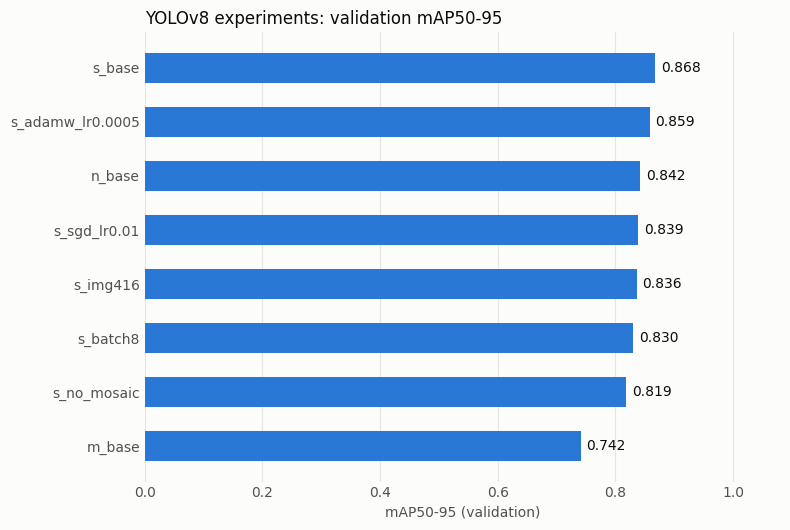

In [ ]:
import matplotlib.pyplot as plt

plot_df = df.sort_values("val_mAP50-95")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(plot_df) + 1.4), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

bars = ax.barh(plot_df["experiment"], plot_df["val_mAP50-95"], height=0.55, color="#2a78d6")
ax.bar_label(bars, fmt="%.3f", padding=4, color="#0b0b0b", fontsize=10)

ax.set_xlim(0, 1.08)
ax.set_xlabel("mAP50-95 (validation)", color="#52514e")
ax.set_title("YOLOv8 experiments: validation mAP50-95", loc="left", color="#0b0b0b", fontsize=12)
ax.xaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(RUNS / "comparison.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

## 8. Best model: per-class performance

This table answers two project questions: which classes are detected well, and which are missed.

- **Low recall** for a class = the model often misses that gesture.
- **Low precision** for a class = the model labels other things as that gesture.

In [ ]:
best_rec = max(records, key=lambda r: r["val"]["map5095"])
print("Best experiment:", best_rec["name"], "| weights:", best_rec["best"])

per_class = pd.DataFrame(best_rec["val"]["per_class"]).T
per_class.round(3)

Best experiment: s_base | weights: /content/rps_runs/s_base/weights/best.pt


,precision,recall,map50,map5095
paper,0.964,0.800,0.977,0.812
rock,1.000,0.856,0.995,0.887
scissors,0.892,0.900,0.947,0.906


## 9. Best model: confusion matrix and training curves

The confusion matrix shows which gesture gets confused with which. The curves show whether training converged or overfit (train loss keeps falling while validation loss rises).

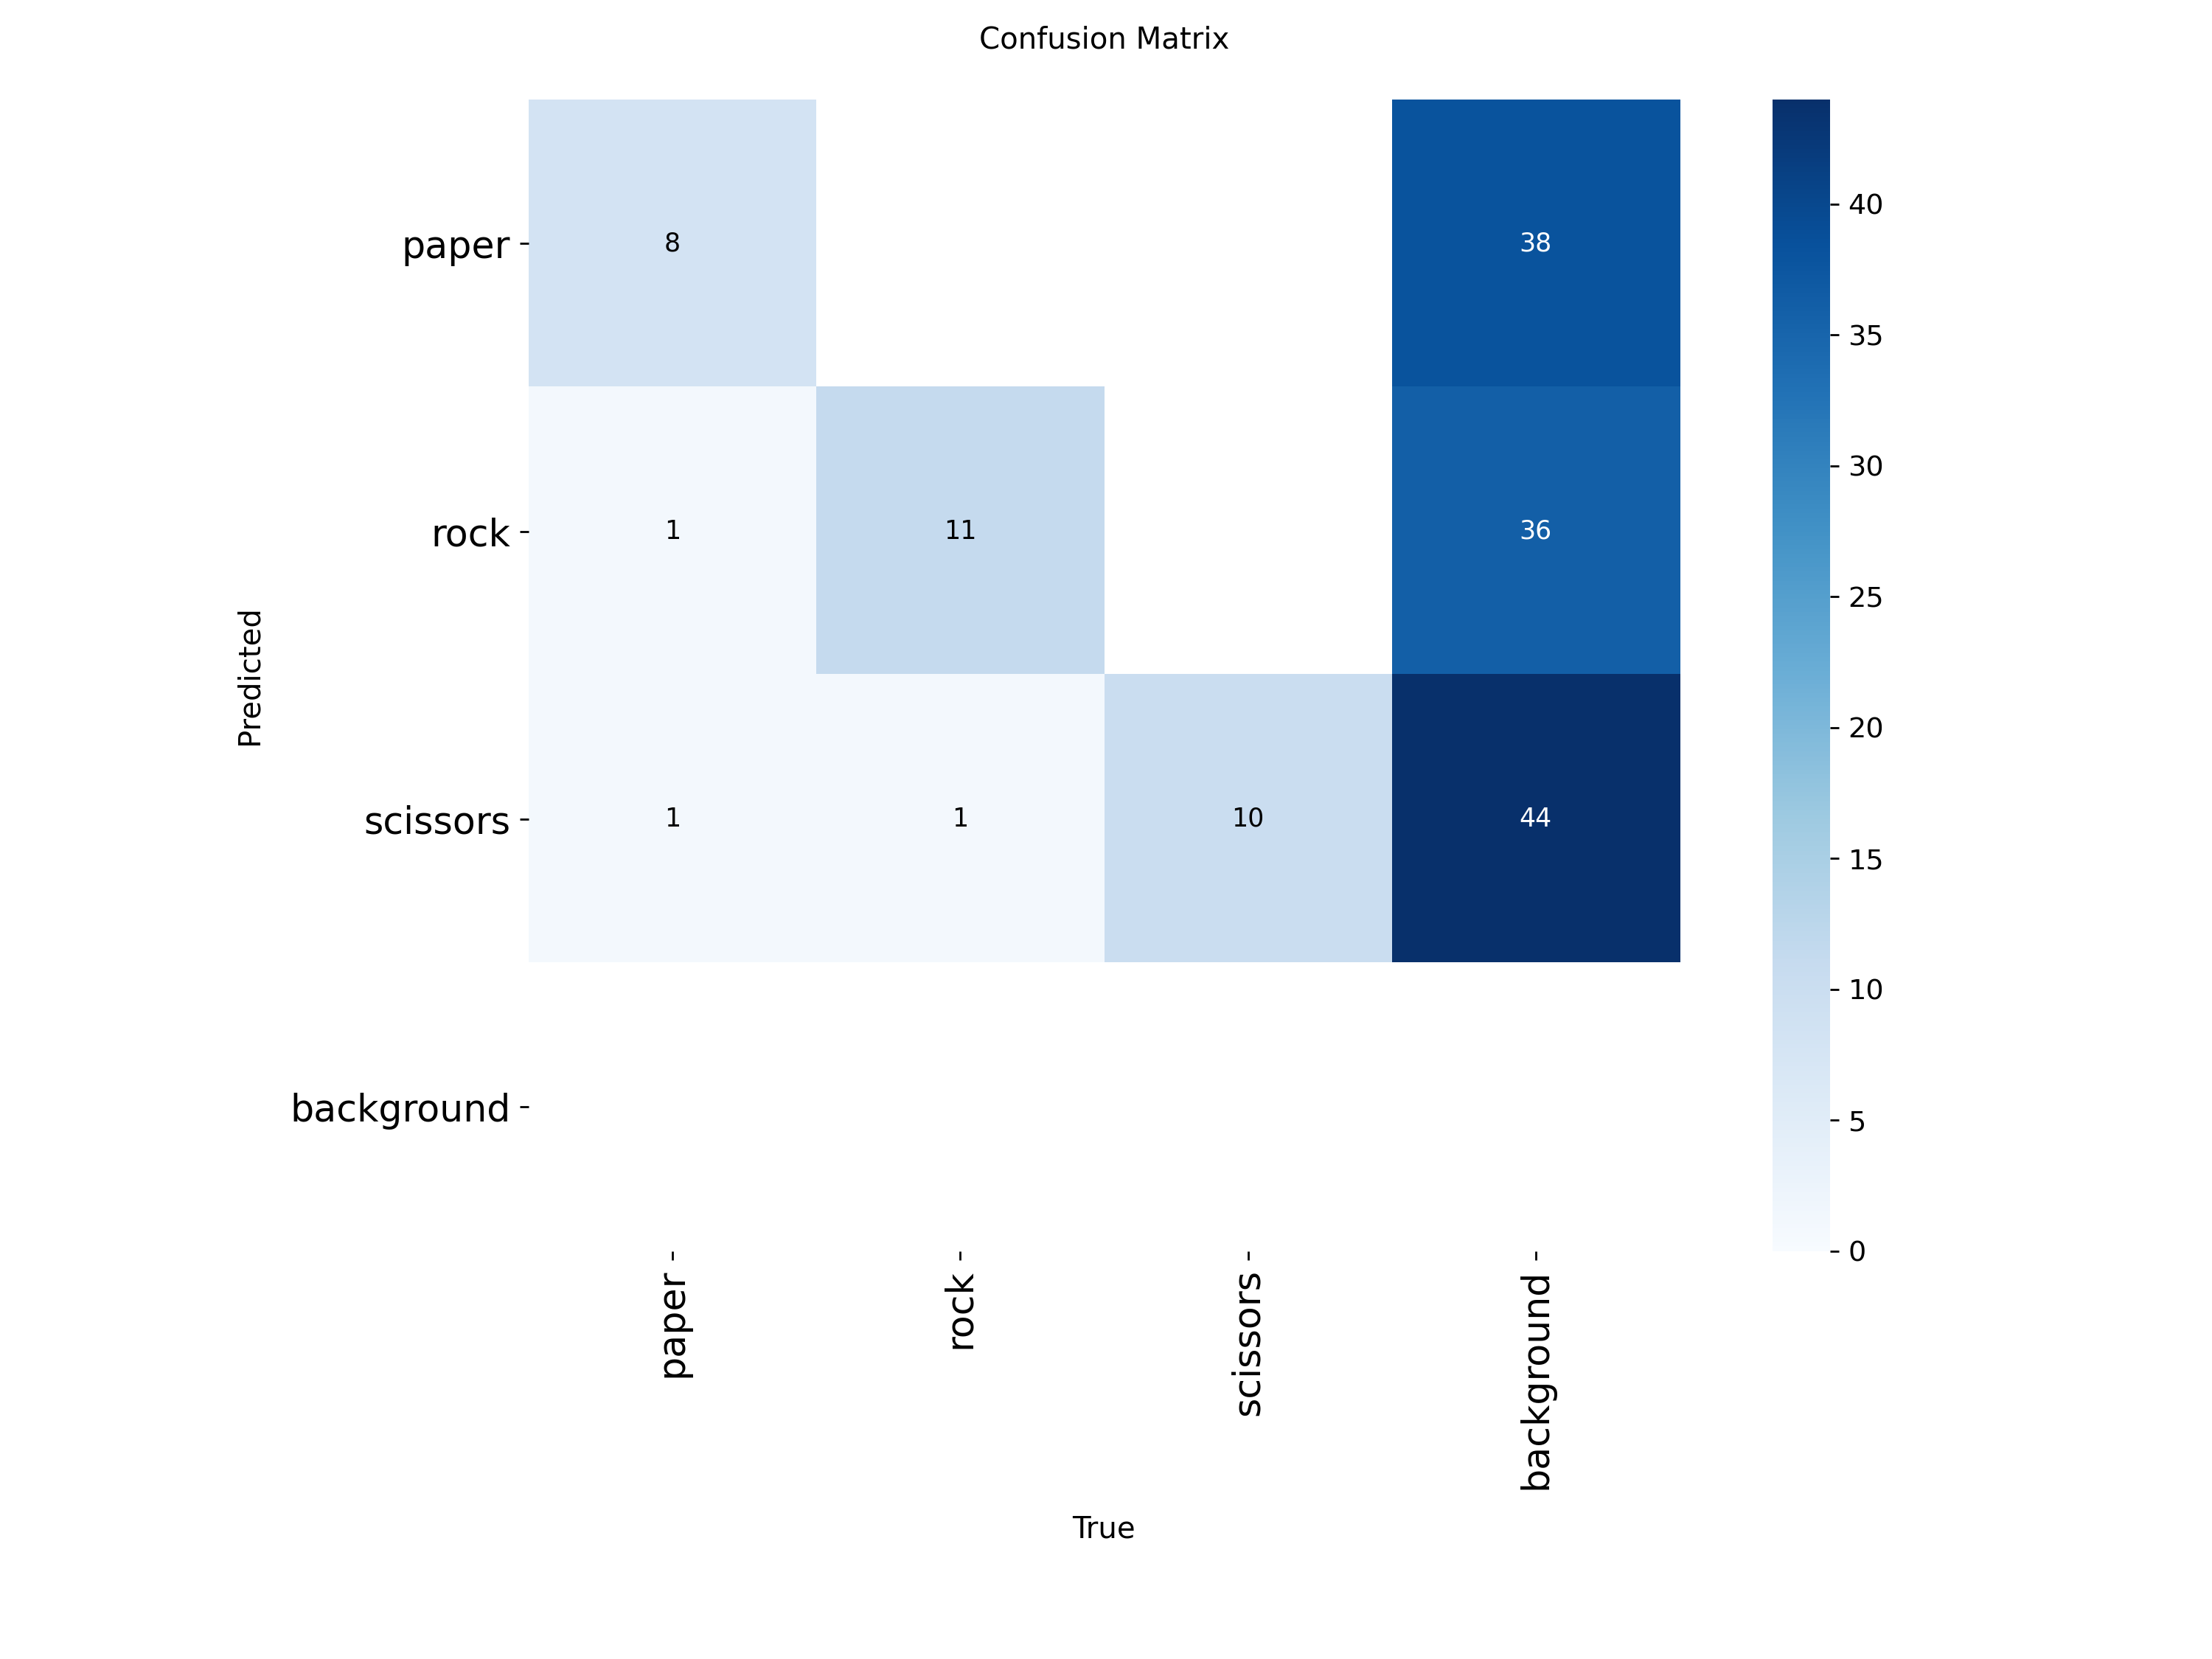

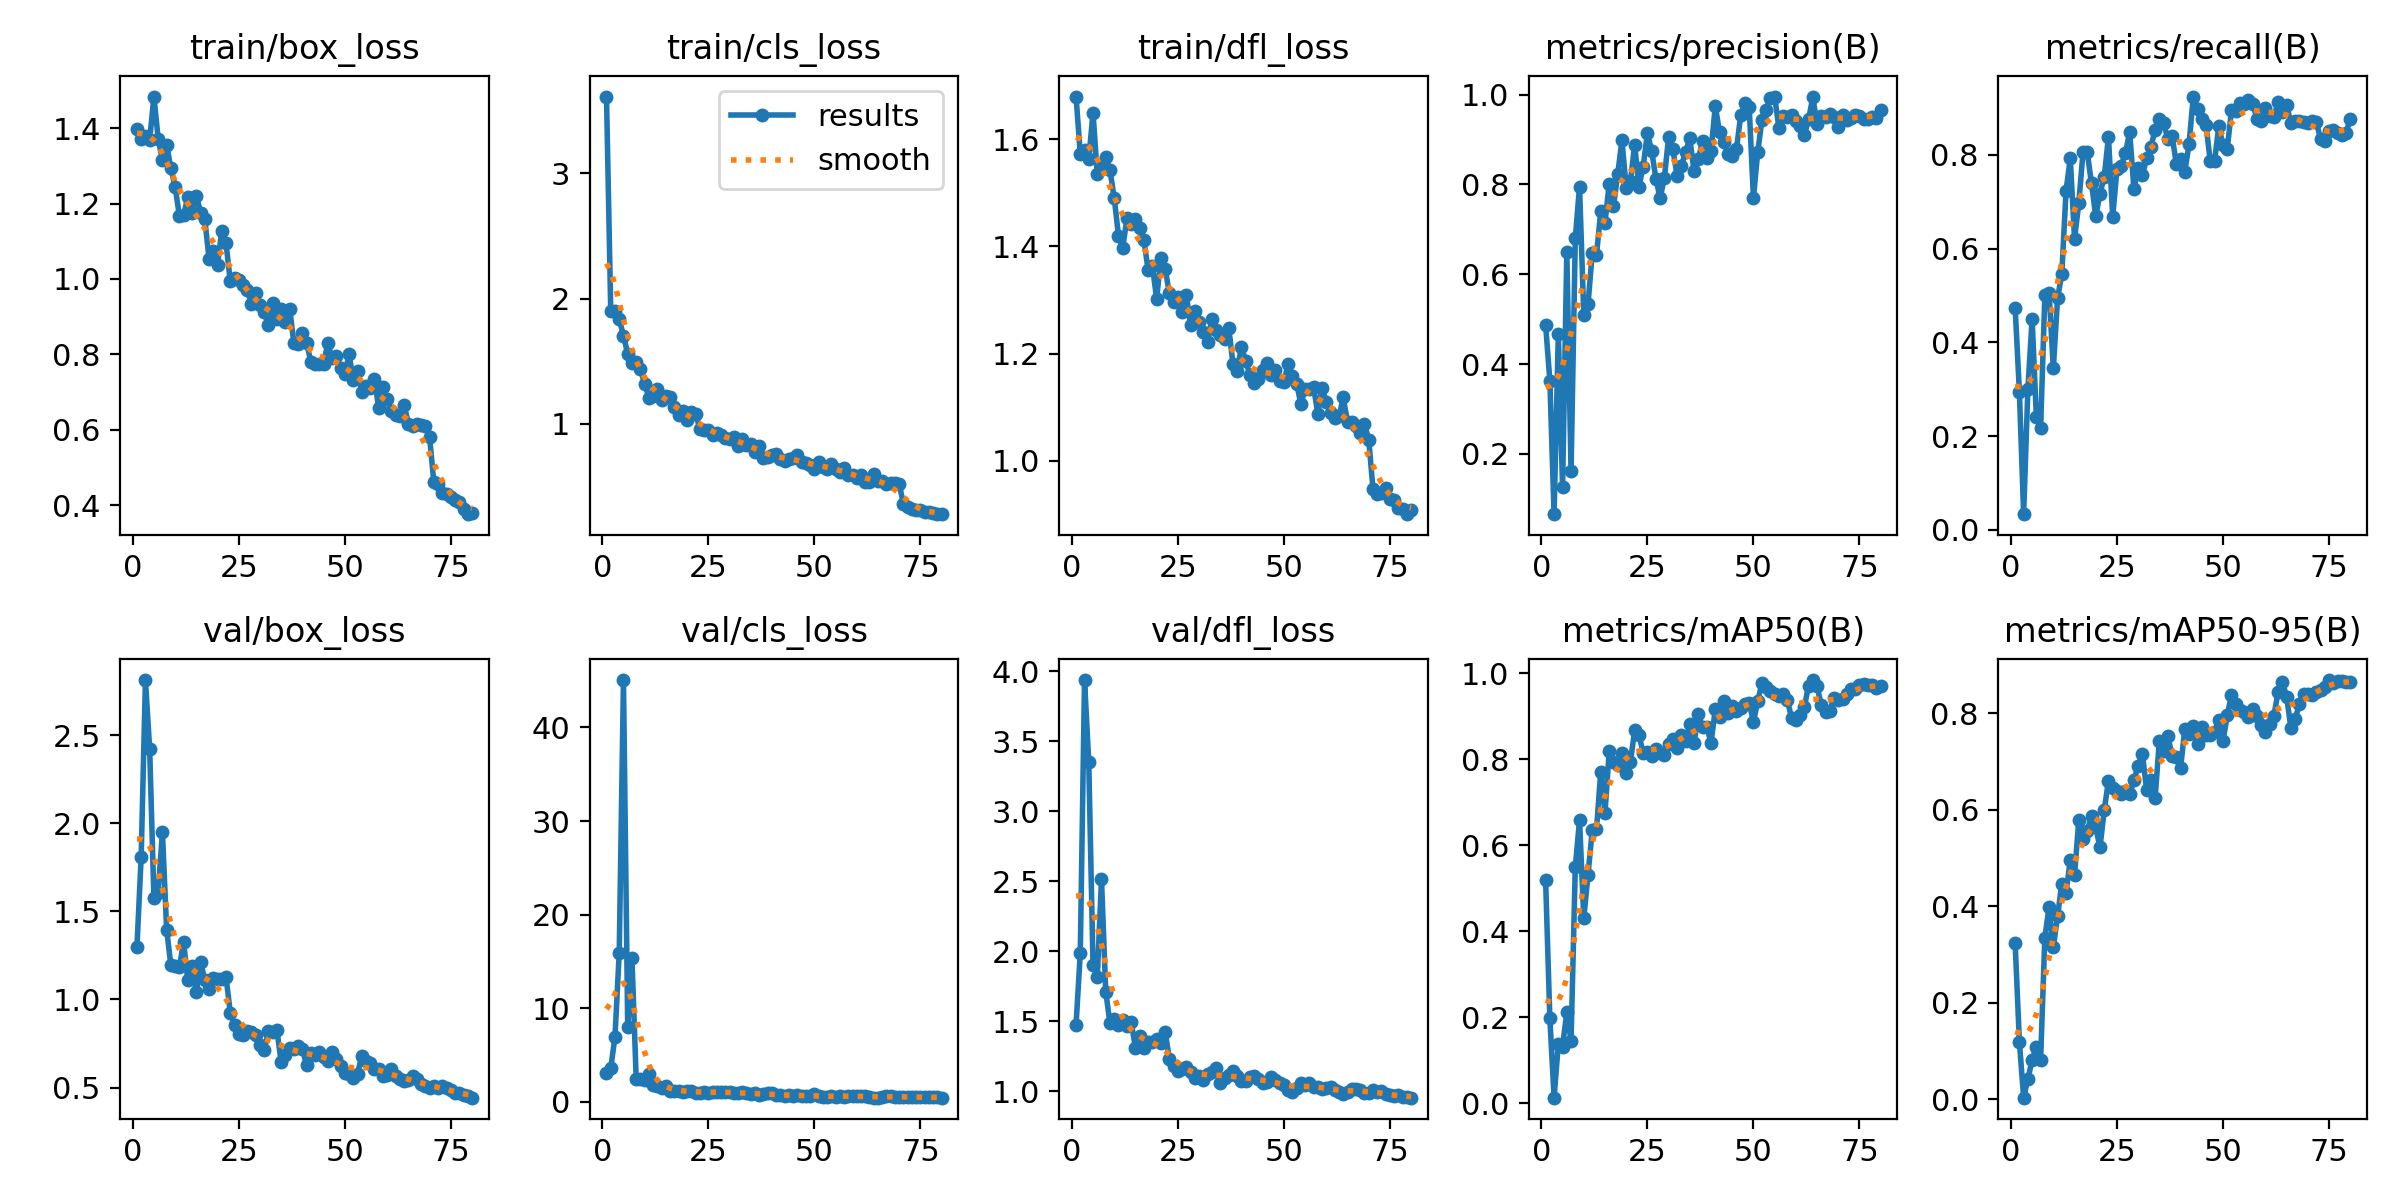

In [ ]:
from IPython.display import Image, display

for fname in ["confusion_matrix.png", "results.png"]:
    p = Path(best_rec["run_dir"]) / fname
    if p.exists():
        display(Image(filename=str(p), width=800))
    else:
        print("not found:", p)

## 10. Testing the best model on test images

If the test folder is empty, the validation images are used instead.

Results saved to /content/rps_runs/test_predictions


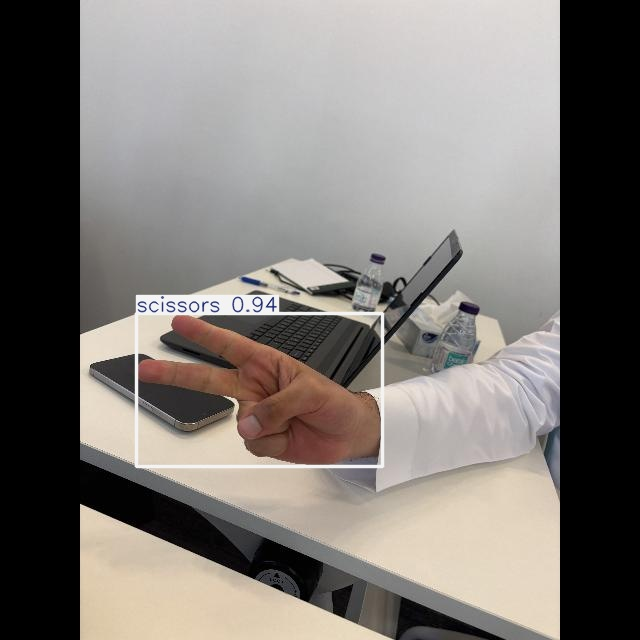

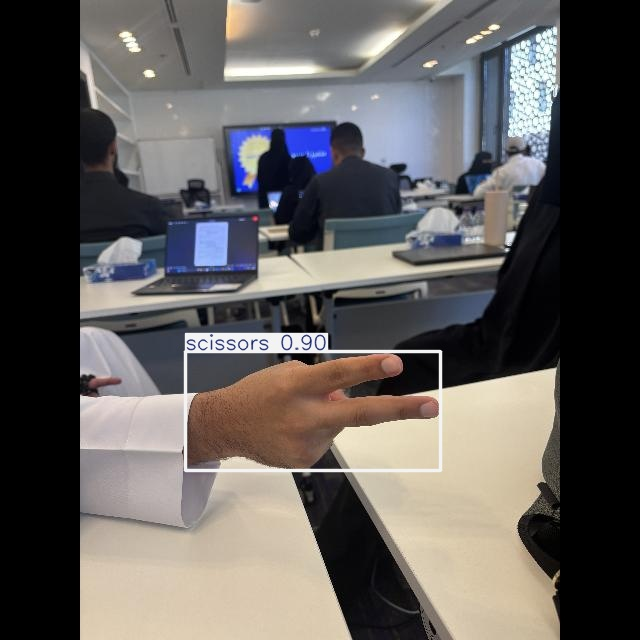

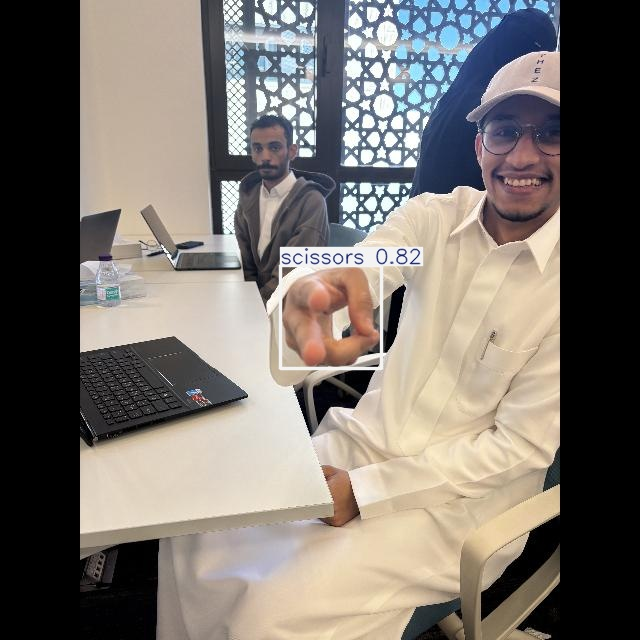

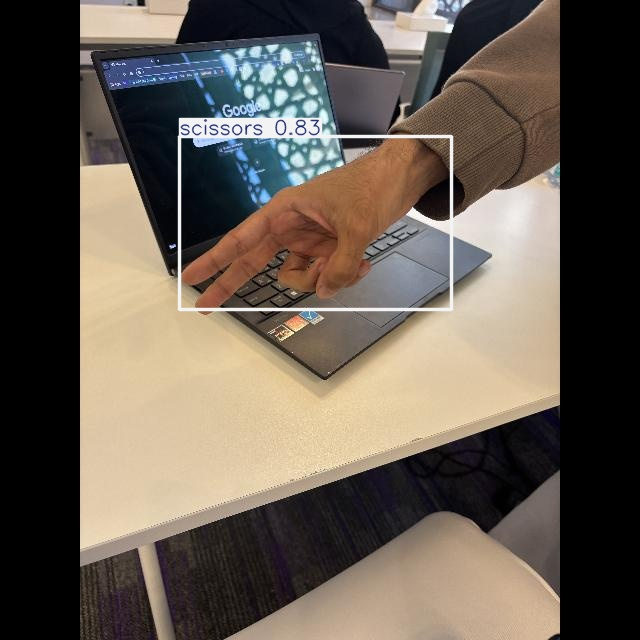

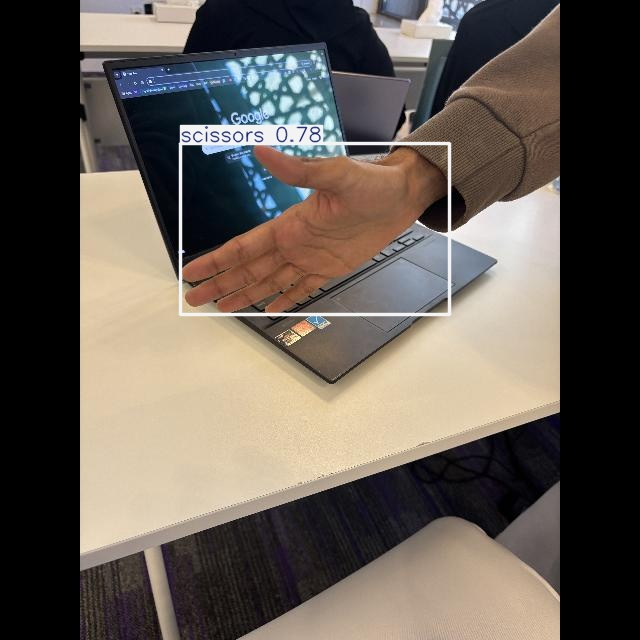

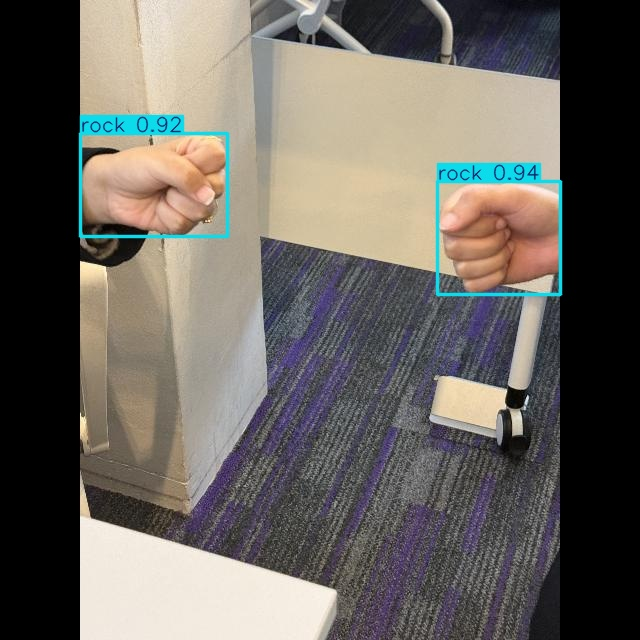

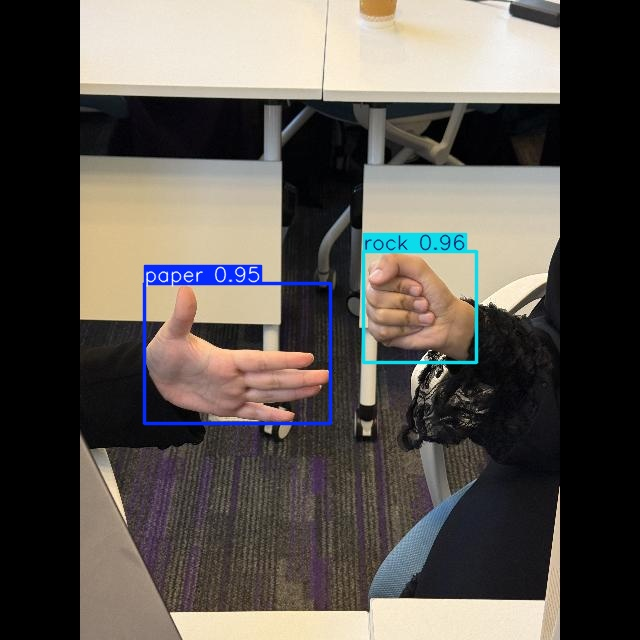

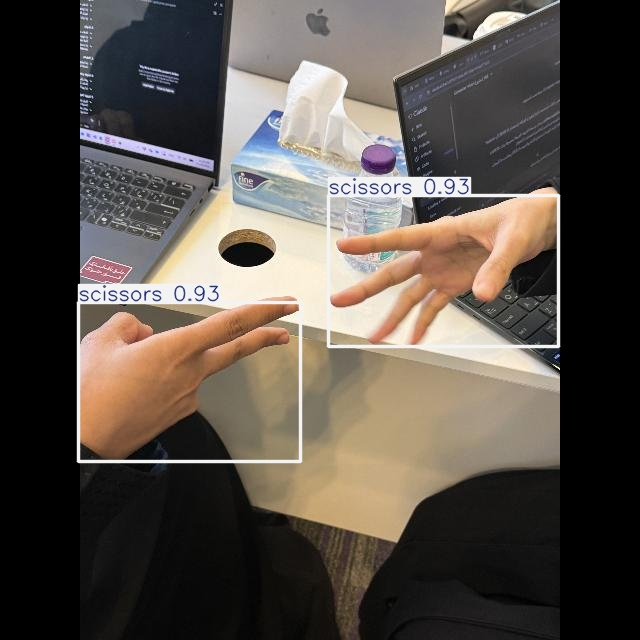

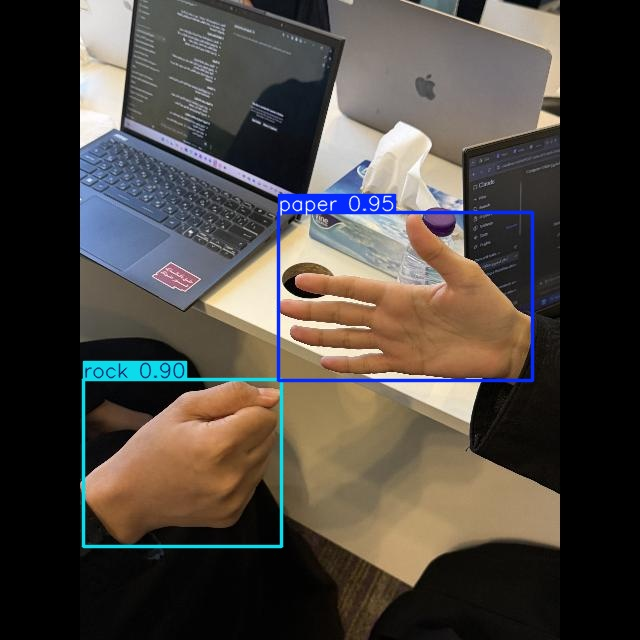

In [ ]:
best_model = YOLO(best_rec["best"])

source = Path(dataset.location) / "test" / "images"
if not source.exists() or not any(source.iterdir()):
    source = Path(dataset.location) / "valid" / "images"

preds = best_model.predict(
    source=str(source),
    imgsz=best_rec["settings"]["imgsz"],
    conf=0.5,
    save=True,
    project=str(RUNS),
    name="test_predictions",
    exist_ok=True,
    verbose=False,
)

for p in sorted(Path(preds[0].save_dir).glob("*.jpg"))[:9]:
    display(Image(filename=str(p), width=320))

## 11. Download the best model and the comparison table

`best.pt` is the file you need for the Gradio or Streamlit app.

In [ ]:
from google.colab import files

files.download(best_rec["best"])
files.download(str(RUNS / "comparison.csv"))
files.download(str(RUNS / "comparison.png"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>